<a href="https://colab.research.google.com/github/prabhnoor14/walmart-hurricane-project/blob/main/notebooks/2026-10-30%20%E2%80%94%20Midterm%20Progress%20%E2%80%94%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import os

if not os.path.exists('/content/walmart-hurricane-project'):
    !git clone https://github.com/prabhnoor14/walmart-hurricane-project.git

walmart_transactions = pd.read_csv(
    '/content/walmart-hurricane-project/data/walmart_transactions.csv'
)

walmart_transactions_copy = walmart_transactions.drop_duplicates().copy()

walmart_transactions_copy['unit_price'] = (
    walmart_transactions_copy['unit_price']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.strip()
    .astype(float)
)

walmart_transactions_copy['timestamp'] = pd.to_datetime(
    walmart_transactions_copy['timestamp'],
    errors='coerce',
    format='mixed'
)

walmart_transactions_copy['transaction_date'] = (
    walmart_transactions_copy['timestamp'].dt.normalize()
)

walmart_transactions_copy['category'] = (
    walmart_transactions_copy['category'].str.strip().str.title()
)

category_mapping = {
    'Alcoholic Beverages': 'Alcohol',
    'Baby Products': 'Baby',
    'Breakfast Foods': 'Breakfast',
    'Emergency Supplies': 'Emergency',
    'Games & Entertainment': 'Entertainment',
    'Groceries': 'Grocery',
    'Health & Wellness': 'Health',
    'Household Essentials': 'Household'
}

walmart_transactions_copy['category'] = (
    walmart_transactions_copy['category'].replace(category_mapping)
)

q1_transactions = walmart_transactions_copy.dropna(
    subset=['transaction_date']
).copy()

q1_baseline = q1_transactions[
    q1_transactions['transaction_date'].between(
        '2024-09-01', '2024-09-14'
    )
].copy()

q1_surge = q1_transactions[
    q1_transactions['transaction_date'].between(
        '2024-09-19', '2024-09-25'
    )
].copy()

baseline_avg = q1_baseline.groupby('category')['quantity'].sum() / 14
surge_avg = q1_surge.groupby('category')['quantity'].sum() / 7

q1_comparison = pd.DataFrame({
    'baseline_daily_avg': baseline_avg,
    'surge_daily_avg': surge_avg
})

q1_comparison['surge_multiple'] = (
    q1_comparison['surge_daily_avg']
    / q1_comparison['baseline_daily_avg']
)

q1_comparison['percent_change'] = (
    (q1_comparison['surge_multiple'] - 1) * 100
)

q1_comparison = q1_comparison.sort_values(
    'percent_change', ascending=False
)

print('Baseline window: September 1-14, 2024 (14 days)')
print('Surge window: September 19-25, 2024 (7 days)')
print('Valid transactions:', len(q1_transactions))
print()
print(q1_comparison.round(2))
print()
print('Top category:', q1_comparison.index[0])
print('Baseline daily average:', round(q1_comparison.iloc[0]['baseline_daily_avg'], 2))
print('Surge daily average:', round(q1_comparison.iloc[0]['surge_daily_avg'], 2))
print('Surge multiple:', round(q1_comparison.iloc[0]['surge_multiple'], 2))
print('Percentage increase:', round(q1_comparison.iloc[0]['percent_change'], 2))

Baseline window: September 1-14, 2024 (14 days)
Surge window: September 19-25, 2024 (7 days)
Valid transactions: 24648

               baseline_daily_avg  surge_daily_avg  surge_multiple  \
category                                                             
Breakfast                   73.64           375.71            5.10   
Emergency                  355.36          1002.29            2.82   
Electronics                 69.57           175.29            2.52   
Alcohol                     61.29           138.29            2.26   
Health                      42.00            94.14            2.24   
Entertainment              102.21           227.00            2.22   
Household                   84.86           175.86            2.07   
Grocery                    171.43           305.29            1.78   
Baby                        84.93           132.57            1.56   
Snacks                      58.79            73.71            1.25   

               percent_change  
categor

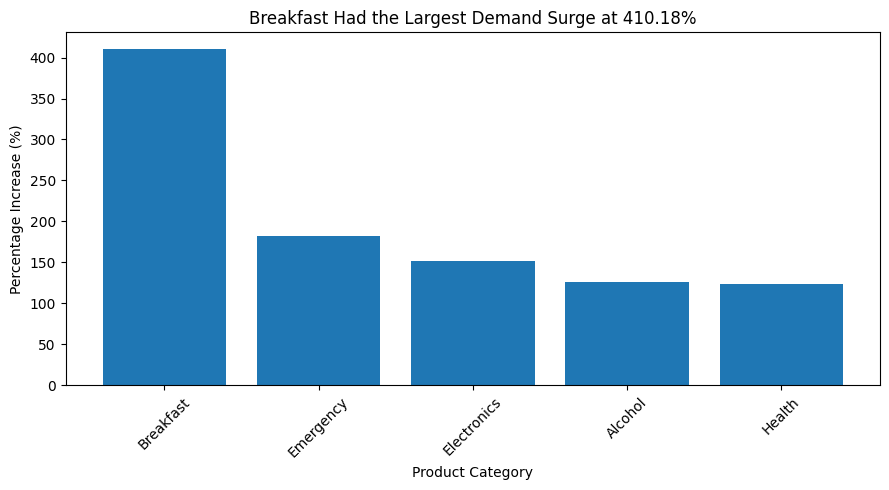

In [8]:
q1_top5 = q1_comparison.head(5)

plt.figure(figsize=(9, 5))

plt.bar(
    q1_top5.index,
    q1_top5['percent_change']
)

top_category = q1_comparison.index[0]
top_increase = q1_comparison.iloc[0]['percent_change']

plt.title(
    f'{top_category} Had the Largest Demand Surge at {top_increase:.2f}%'
)
plt.xlabel('Product Category')
plt.ylabel('Percentage Increase (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Q1 answer, in one sentence a manager could read:** Breakfast had the largest increase in demand before the hurricane, with average daily sales rising from 73.64 units during September 1–14 to 375.71 units during September 19–25, a 5.10 times increase (410.18%).

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

In [ ]:
# TODO

**Q2 answer:** _..._

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

In [ ]:
# TODO

**Q3 answer, with its caveat:** _..._

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** I found that demand increased across all 12 Walmart stores before the hurricane, but some locations had larger increases than others. Miami had the highest increase at 172.52%, while Orlando had the lowest at 123.70%. I also found that demand increased across all six Florida regions. I've completed the comparisons and charts and am reviewing my results before the presentation.

**Owner: Norah Munoz**

**Q5 (signal or artifact):** It is a signal as well as an artifact because while there is not an +250% increse in entertainment sales during the surge period, there was an increase of around +220%. This increase is not fully transparent because the walmart transactions has rows that did not have timestamps and negative units. There were several record of entertainment supplies in the walmart with missing timestamp in the transaction table and they could not be matched to a specific date.

**Owner: Safaa Mahbub**

### Self-check

In [ ]:
progress = {
    'q1_multiple': None,            # TODO: a number
    'q1_baseline_window': 'TODO',   # TODO: stated explicitly
    'q2_canonical_products': None,  # TODO: a number
    'q3_join_rows_preserved': None, # TODO: True/False
    'q3_days_in_correlation': None, # TODO: a number
    'charts_with_message_titles': None,  # TODO: how many
    'notebook_runs_clean': False,   # TODO: True after Restart and Run All
    'repo_pushed': False,           # TODO
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

_your answer here_